# MOM6 Input Files for anu-tub

This case is designed to run MOM6 with the tub sector domain, at 0.25° resolution. 

The input files are saved in netcdf format, and need to copied into the relevant input directories before the run.

In [1]:
%matplotlib inline
import xarray as xr
import numpy as np
import netCDF4 as nc
import matplotlib.pyplot as plt

## Set up domain size and parameters

In [2]:
REa=6.37*10**6     # Radius of Earth
D = 4000           # Water depth
nx = 100           # number of gridpoints in x, y and z
ny = 100
nz = 100
rx = 5_000           # base resolution, in meters

## Now, to make the horizontal grid - Cartesian grid

In [3]:
dy = np.zeros(ny,)           # grid length
y = np.zeros(ny,)            # grid points
Ystart=0.000
dy[0] = rx
y[0] = Ystart + 0.5*rx# *np.cos(Ystart*np.pi/180.)
for i in range(ny-1):
    y[i+1] = y[i] + dy[i]
    dy[i+1] = rx #*np.cos(y[i+1]*np.pi/180.)

Yend = y[-1] + dy[-1]/2
print(' Domain goes from:',Ystart, ' to:', Yend)

# longitudinal grid is a bit easier.
dx = np.ones(nx,)*rx
x = np.cumsum(dx)-dx/2

# Make a mesh of grids.
X,Y = np.meshgrid(x,y)
#DX,DY = np.meshgrid(dx,dy)

#diff = Yend + Ystart
print(y)

 Domain goes from: 0.0  to: 500000.0
[  2500.   7500.  12500.  17500.  22500.  27500.  32500.  37500.  42500.
  47500.  52500.  57500.  62500.  67500.  72500.  77500.  82500.  87500.
  92500.  97500. 102500. 107500. 112500. 117500. 122500. 127500. 132500.
 137500. 142500. 147500. 152500. 157500. 162500. 167500. 172500. 177500.
 182500. 187500. 192500. 197500. 202500. 207500. 212500. 217500. 222500.
 227500. 232500. 237500. 242500. 247500. 252500. 257500. 262500. 267500.
 272500. 277500. 282500. 287500. 292500. 297500. 302500. 307500. 312500.
 317500. 322500. 327500. 332500. 337500. 342500. 347500. 352500. 357500.
 362500. 367500. 372500. 377500. 382500. 387500. 392500. 397500. 402500.
 407500. 412500. 417500. 422500. 427500. 432500. 437500. 442500. 447500.
 452500. 457500. 462500. 467500. 472500. 477500. 482500. 487500. 492500.
 497500.]


## Now make land and bathymetry

In [4]:
## make land:
dc=59
h = - D*(2**(-0.4*X**2)*(1-0.5*2**(-0.003*abs(-Y-dc)**4)) - 0.9)/0.9
h = h - D*(2**(-0.4*(X-nx*rx)**2)*(1-0.5*2**(-0.003*abs(-Y-dc)**4)) - 0.9)/0.9 - D
h = np.where(h<0,0,h)

## add matching shelves on all four boundaries
shelf_depth = 0
sws = 3*rx  # shelf-width scale in meters

# Distance to the nearest domain edge
edge_dist = np.minimum.reduce([
    X,                   # western edge
    nx * rx - X,         # eastern edge
    Y - Ystart,          # southern edge
    Yend - Y             # northern edge
])

# Smooth transition from shelf depth to full depth over 3*sws meters
t = np.clip(edge_dist / (3 * sws), 0, 1)
htmp = shelf_depth + (D - shelf_depth) * (3 * t**2 - 2 * t**3)

# Limit ocean depths to the shelf profile; retain land
h = np.minimum(h, htmp)



Text(0.5, 1.0, 'topog')

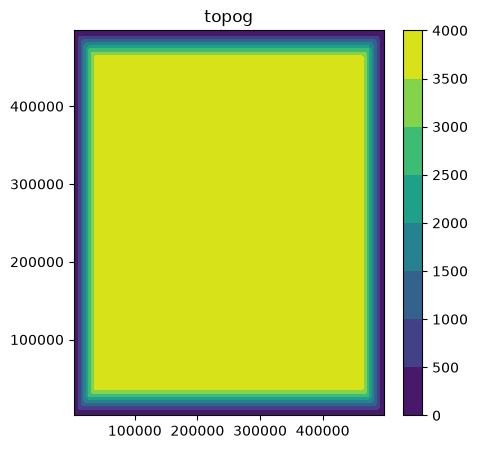

In [5]:
hda  = xr.DataArray(h, 
                  coords=[('y', y),('x', x)], 
                  name='topog',)

hda.to_netcdf('topog.nc')

# plot for posterity
fig, ax = plt.subplots(figsize=(5,5))

cf = ax.contourf(x,y, hda)
cbar = fig.colorbar(cf)
plt.title('topog')

# plt.subplot(122)
# hda.isel(y=10).plot()
# hda.isel(y=-59).plot()





# Now construct wind stress forcing
For now, just make reference case.


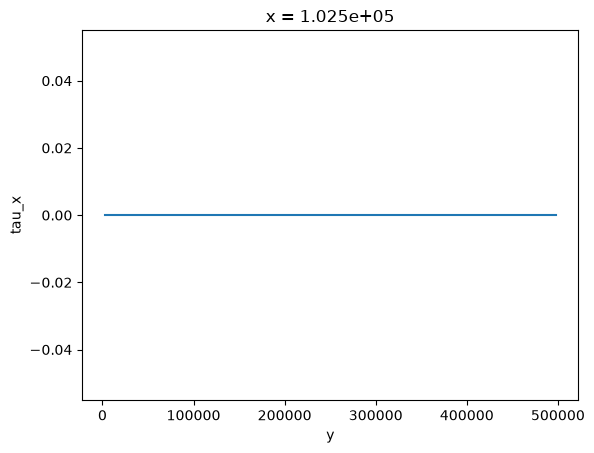

In [6]:
# Wind stress

tau_x = 0.00*X #0.03*(np.cos(np.pi*(Y-y[int(ny/2)])/(y[-1]-y[0]))) 

tau_y = tau_x

tau_ds = xr.Dataset({'tau_x': (['y', 'x'],  tau_x),
                     'tau_y': (['y', 'x'], tau_y),
                     'SSS': (['y', 'x'], np.zeros((ny,nx))),
                     'LW': (['y', 'x'], np.zeros((ny,nx))),
                     'SW': (['y', 'x'], np.zeros((ny,nx))),
                     'froz_precip': (['y', 'x'], np.zeros((ny,nx))),
                     'froz_runoff': (['y', 'x'], np.zeros((ny,nx))),
                     'latent': (['y', 'x'], np.zeros((ny,nx))),
                     'liq_precip': (['y', 'x'], np.zeros((ny,nx))),
                     'liq_runoff': (['y', 'x'], np.zeros((ny,nx))),
                     'sensible': (['y', 'x'], np.zeros((ny,nx))),
                     'evap': (['y', 'x'], np.zeros((ny,nx)))},
                     coords={'x': (['x'], x),'y': (['y'], y)},)

#plot
tau_ds.tau_x.isel(x=20).plot()

tau_ds.to_netcdf('forcing.nc')